In [1]:
# Assignment 9: Feature Importance Visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import r2_score, mean_absolute_error, f1_score, recall_score, precision_score

import warnings
warnings.filterwarnings("ignore")

In [2]:
# Part A: Vehicle price (regression) using the UCI Automobile dataset

cars = pd.read_csv("automobile.csv")

print("Dataset loaded successfully.")
print("Shape:", cars.shape)
cars.head()

Dataset loaded successfully.
Shape: (205, 26)


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


In [3]:
cars = cars.replace("?", np.nan)

for column in ["normalized-losses", "bore", "stroke", "horsepower", "peak-rpm", "price"]:
    cars[column] = pd.to_numeric(cars[column])

cars = cars.dropna(subset=["price"])

for column in ["normalized-losses", "bore", "stroke", "horsepower", "peak-rpm"]:
    cars[column] = cars[column].fillna(cars[column].median())

cars["num-of-doors"] = cars["num-of-doors"].fillna(cars["num-of-doors"].mode()[0])

word_to_number = {
    "two": 2,
    "three": 3,
    "four": 4,
    "five": 5,
    "six": 6,
    "eight": 8,
    "twelve": 12
}

cars["num-of-doors"] = cars["num-of-doors"].map(word_to_number)
cars["num-of-cylinders"] = cars["num-of-cylinders"].map(word_to_number)

print("Total missing values remaining:", cars.isnull().sum().sum())
print("Shape:", cars.shape)

Total missing values remaining: 0
Shape: (201, 26)


In [4]:
car_categorical = [
    "make",
    "fuel-type",
    "aspiration",
    "body-style",
    "drive-wheels",
    "engine-location",
    "engine-type",
    "fuel-system"
]

car_numeric = [
    column for column in cars.columns
    if column not in car_categorical + ["price"]
]

# Numeric columns are stored as float so partial dependence can
# evaluate values between the whole numbers in the data
X_cars = cars[car_numeric + car_categorical].astype({column: float for column in car_numeric})
y_cars = cars["price"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cars,
    y_cars,
    test_size=0.20,
    random_state=42
)

print("Numeric features    :", len(car_numeric))
print("Categorical features:", len(car_categorical))
print("Training samples    :", Xc_train.shape[0])
print("Testing samples     :", Xc_test.shape[0])

Numeric features    : 17
Categorical features: 8
Training samples    : 160
Testing samples     : 41


In [5]:
# The encoder sits inside the pipeline, so permutation importance can later
# shuffle the original columns instead of individual one-hot columns
car_forest = Pipeline([
    ("prepare", ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore"), car_categorical)
    ], remainder="passthrough", verbose_feature_names_out=False)),
    ("model", RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))
])

car_forest.fit(Xc_train, yc_train)

car_predictions = car_forest.predict(Xc_test)

print("Random Forest - vehicle price")
print("R2 score:", round(r2_score(yc_test, car_predictions), 3))
print("MAE     :", round(mean_absolute_error(yc_test, car_predictions), 2))

Random Forest - vehicle price
R2 score: 0.929
MAE     : 1884.61


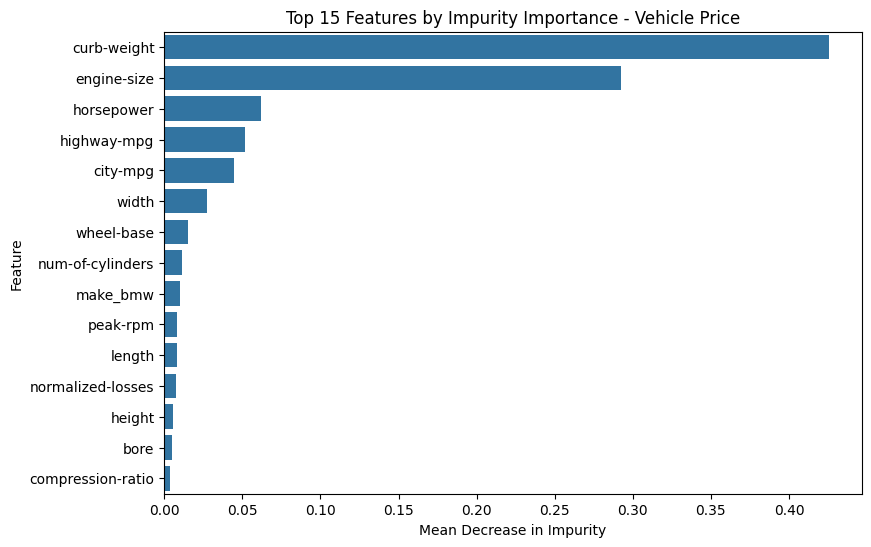

,Feature,Importance
57,curb-weight,0.425347
59,engine-size,0.292270
63,horsepower,0.062180
66,highway-mpg,0.051929
65,city-mpg,0.044486
55,width,0.027248
53,wheel-base,0.015060
58,num-of-cylinders,0.011164
2,make_bmw,0.009778
64,peak-rpm,0.008319


In [6]:
# Method 1: impurity based importance (built into the random forest)
encoded_names = car_forest.named_steps["prepare"].get_feature_names_out()

car_impurity = pd.DataFrame({
    "Feature": encoded_names,
    "Importance": car_forest.named_steps["model"].feature_importances_
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=car_impurity.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features by Impurity Importance - Vehicle Price")
plt.xlabel("Mean Decrease in Impurity")
plt.ylabel("Feature")
plt.show()

car_impurity.head(15)

In [7]:
# One-hot columns such as make_bmw and make_porsche are added back
# together so each original feature gets a single score
def original_feature(encoded_name):
    for column in car_categorical:
        if encoded_name.startswith(column + "_"):
            return column
    return encoded_name


car_impurity["Original Feature"] = car_impurity["Feature"].apply(original_feature)

car_impurity_grouped = (
    car_impurity.groupby("Original Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

car_impurity_grouped.head(10)

,Original Feature,Importance
0,curb-weight,0.425347
1,engine-size,0.292270
2,horsepower,0.062180
3,highway-mpg,0.051929
4,city-mpg,0.044486
5,width,0.027248
6,wheel-base,0.015060
7,make,0.014219
8,num-of-cylinders,0.011164
9,peak-rpm,0.008319


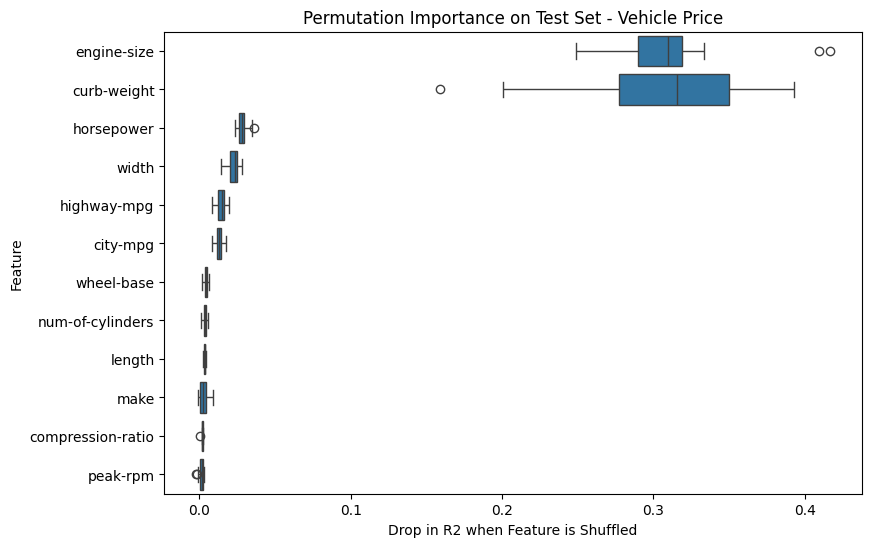

,Feature,Mean,Std
9,engine-size,0.3118,0.0405
7,curb-weight,0.3038,0.0614
13,horsepower,0.0286,0.0033
5,width,0.0225,0.0037
16,highway-mpg,0.0143,0.0030
15,city-mpg,0.0132,0.0024
3,wheel-base,0.0044,0.0011
8,num-of-cylinders,0.0036,0.0011
4,length,0.0035,0.0006
17,make,0.0030,0.0029


In [8]:
# Method 2: permutation importance on the test set
# Each column is shuffled 20 times and the drop in R2 is recorded
car_permutation = permutation_importance(
    car_forest,
    Xc_test,
    yc_test,
    n_repeats=20,
    random_state=42,
    scoring="r2"
)

car_permutation_df = pd.DataFrame({
    "Feature": X_cars.columns,
    "Mean": car_permutation.importances_mean,
    "Std": car_permutation.importances_std
}).sort_values(by="Mean", ascending=False)

top_permutation = car_permutation_df.head(12)["Feature"].tolist()

permutation_long = pd.DataFrame(
    car_permutation.importances.T,
    columns=X_cars.columns
)[top_permutation].melt(var_name="Feature", value_name="Drop in R2")

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=permutation_long,
    x="Drop in R2",
    y="Feature"
)

plt.title("Permutation Importance on Test Set - Vehicle Price")
plt.xlabel("Drop in R2 when Feature is Shuffled")
plt.ylabel("Feature")
plt.show()

car_permutation_df.head(12).round(4)

In [9]:
car_comparison = car_impurity_grouped.rename(
    columns={"Original Feature": "Feature", "Importance": "Impurity"}
).merge(
    car_permutation_df[["Feature", "Mean"]].rename(columns={"Mean": "Permutation"}),
    on="Feature"
)

car_comparison["Impurity Rank"] = car_comparison["Impurity"].rank(ascending=False).astype(int)
car_comparison["Permutation Rank"] = car_comparison["Permutation"].rank(ascending=False).astype(int)

rank_agreement = car_comparison["Impurity"].corr(
    car_comparison["Permutation"],
    method="spearman"
)

print("Spearman rank correlation between the two methods: %.2f" % rank_agreement)

car_comparison.sort_values(by="Impurity Rank").head(10).round(4)

Spearman rank correlation between the two methods: 0.86


,Feature,Impurity,Permutation,Impurity Rank,Permutation Rank
0,curb-weight,0.4253,0.3038,1,2
1,engine-size,0.2923,0.3118,2,1
2,horsepower,0.0622,0.0286,3,3
3,highway-mpg,0.0519,0.0143,4,5
4,city-mpg,0.0445,0.0132,5,6
5,width,0.0272,0.0225,6,4
6,wheel-base,0.0151,0.0044,7,7
7,make,0.0142,0.0030,8,10
8,num-of-cylinders,0.0112,0.0036,9,8
9,peak-rpm,0.0083,0.0012,10,12


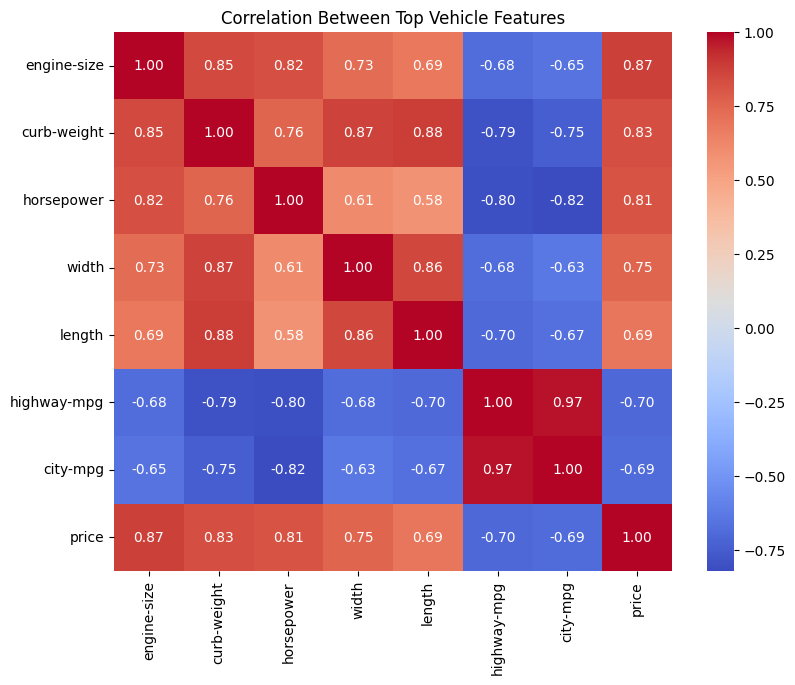

In [10]:
# Size related features are strongly correlated with each other, so the
# forest can use any of them and their importance is shared between them
size_features = [
    "engine-size",
    "curb-weight",
    "horsepower",
    "width",
    "length",
    "highway-mpg",
    "city-mpg",
    "price"
]

plt.figure(figsize=(9, 7))

sns.heatmap(
    cars[size_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Top Vehicle Features")
plt.show()

Ridge regression R2 (numeric features only): 0.769


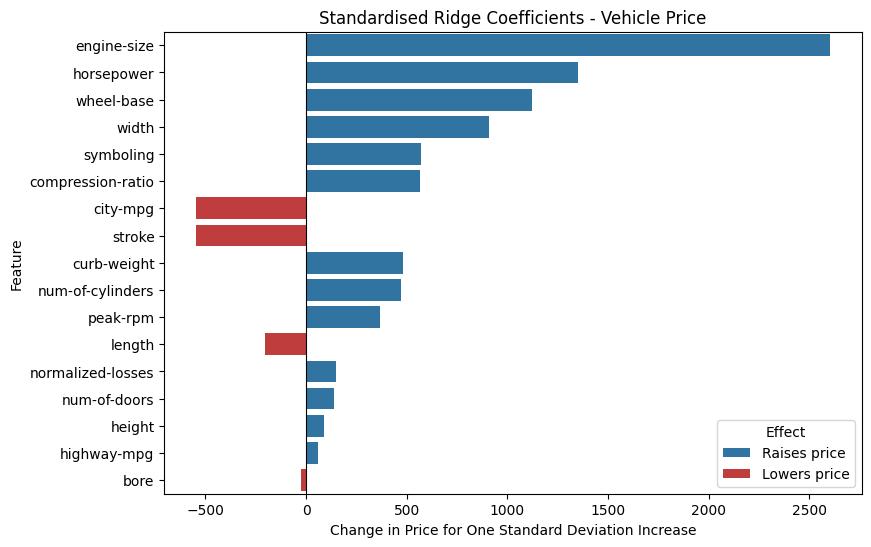

,Feature,Coefficient,Effect
9,engine-size,2602.3,Raises price
13,horsepower,1349.7,Raises price
3,wheel-base,1120.9,Raises price
5,width,906.2,Raises price
0,symboling,570.3,Raises price
12,compression-ratio,567.2,Raises price
15,city-mpg,-546.5,Lowers price
11,stroke,-546.2,Lowers price
7,curb-weight,480.6,Raises price
8,num-of-cylinders,473.8,Raises price


In [11]:
# Method 3: standardised coefficients of a linear model
# Tree importance has no sign, the coefficients show the direction of the effect
car_ridge = Pipeline([
    ("scale", StandardScaler()),
    ("model", Ridge(alpha=10.0))
])

car_ridge.fit(Xc_train[car_numeric], yc_train)

print("Ridge regression R2 (numeric features only):",
      round(r2_score(yc_test, car_ridge.predict(Xc_test[car_numeric])), 3))

car_coefficients = pd.DataFrame({
    "Feature": car_numeric,
    "Coefficient": car_ridge.named_steps["model"].coef_
}).sort_values(by="Coefficient", key=abs, ascending=False)

car_coefficients["Effect"] = np.where(
    car_coefficients["Coefficient"] > 0,
    "Raises price",
    "Lowers price"
)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=car_coefficients,
    x="Coefficient",
    y="Feature",
    hue="Effect",
    palette={"Raises price": "tab:blue", "Lowers price": "tab:red"},
    dodge=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Standardised Ridge Coefficients - Vehicle Price")
plt.xlabel("Change in Price for One Standard Deviation Increase")
plt.ylabel("Feature")
plt.show()

car_coefficients.round(1)

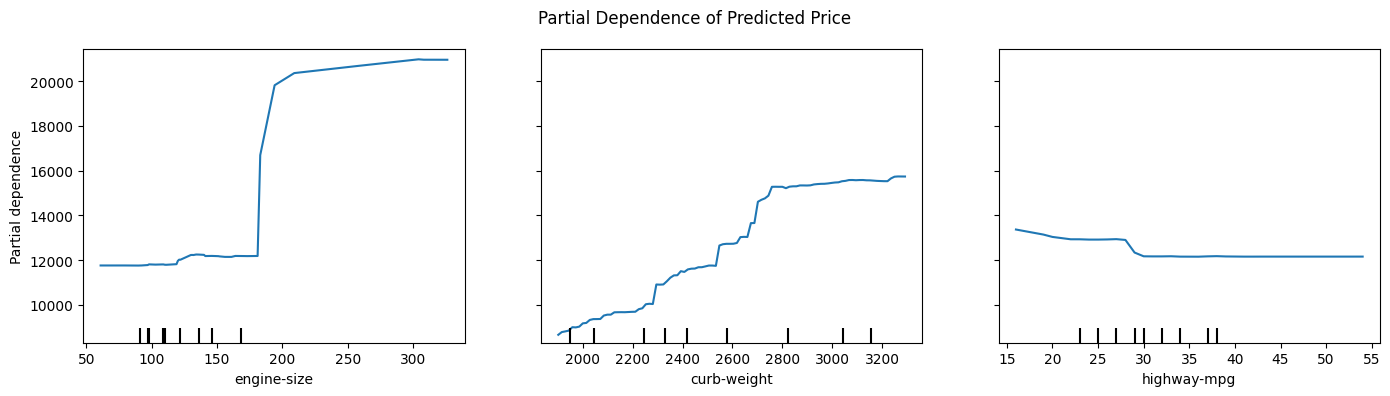

In [12]:
# Method 4: partial dependence shows how the predicted price changes
# as one feature changes while the others are averaged out
fig, ax = plt.subplots(figsize=(14, 4))

PartialDependenceDisplay.from_estimator(
    car_forest,
    Xc_train,
    features=["engine-size", "curb-weight", "highway-mpg"],
    ax=ax
)

fig.suptitle("Partial Dependence of Predicted Price")
plt.tight_layout()
plt.show()

In [13]:
# Part B: Machine failure (classification) using the AI4I 2020 dataset

sensors = pd.read_csv("ai4i2020.csv")

print("Dataset loaded successfully.")
print("Shape:", sensors.shape)
print("Failure rate: %.2f percent" % (sensors["Machine failure"].mean() * 100))
sensors.head()

Dataset loaded successfully.
Shape: (10000, 14)
Failure rate: 3.39 percent


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [14]:
sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X_sensors = pd.get_dummies(
    sensors[sensor_columns + ["Type"]],
    columns=["Type"],
    drop_first=True,
    dtype=int
).astype(float)
y_sensors = sensors["Machine failure"]

Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_sensors,
    y_sensors,
    test_size=0.20,
    random_state=42,
    stratify=y_sensors
)

sensor_forest = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

sensor_forest.fit(Xs_train, ys_train)

sensor_predictions = sensor_forest.predict(Xs_test)

print("Random Forest - machine failure")
print("Precision:", round(precision_score(ys_test, sensor_predictions), 3))
print("Recall   :", round(recall_score(ys_test, sensor_predictions), 3))
print("F1 Score :", round(f1_score(ys_test, sensor_predictions), 3))

Random Forest - machine failure
Precision: 0.919
Recall   : 0.5
F1 Score : 0.648


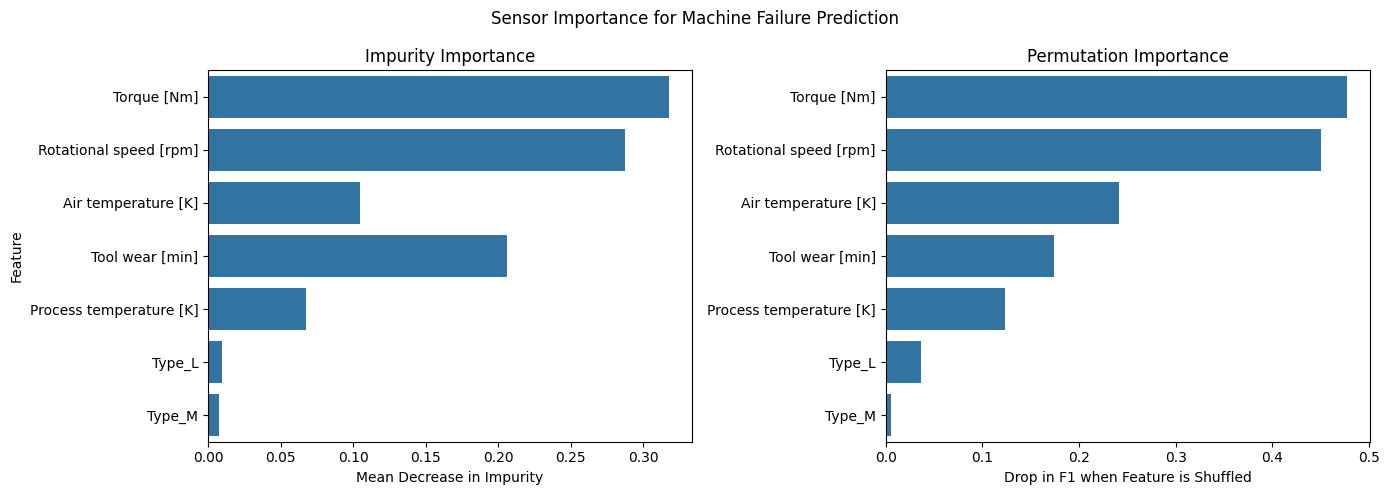

,Impurity,Permutation (drop in F1)
Torque [Nm],0.3177,0.4769
Rotational speed [rpm],0.2870,0.4505
Air temperature [K],0.1047,0.2412
Tool wear [min],0.2062,0.1742
Process temperature [K],0.0676,0.1240
Type_L,0.0095,0.0364
Type_M,0.0073,0.0051


In [15]:
sensor_impurity = pd.Series(
    sensor_forest.feature_importances_,
    index=X_sensors.columns
)

# Failures are rare, so permutation importance is measured with F1
# instead of accuracy, which would barely move
sensor_permutation = permutation_importance(
    sensor_forest,
    Xs_test,
    ys_test,
    n_repeats=20,
    random_state=42,
    scoring="f1"
)

sensor_importance = pd.DataFrame({
    "Impurity": sensor_impurity,
    "Permutation (drop in F1)": pd.Series(
        sensor_permutation.importances_mean,
        index=X_sensors.columns
    )
}).sort_values(by="Permutation (drop in F1)", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    x=sensor_importance["Impurity"],
    y=sensor_importance.index,
    ax=axes[0]
)
axes[0].set_title("Impurity Importance")
axes[0].set_xlabel("Mean Decrease in Impurity")
axes[0].set_ylabel("Feature")

sns.barplot(
    x=sensor_importance["Permutation (drop in F1)"],
    y=sensor_importance.index,
    ax=axes[1]
)
axes[1].set_title("Permutation Importance")
axes[1].set_xlabel("Drop in F1 when Feature is Shuffled")
axes[1].set_ylabel("")

fig.suptitle("Sensor Importance for Machine Failure Prediction")
plt.tight_layout()
plt.show()

sensor_importance.round(4)

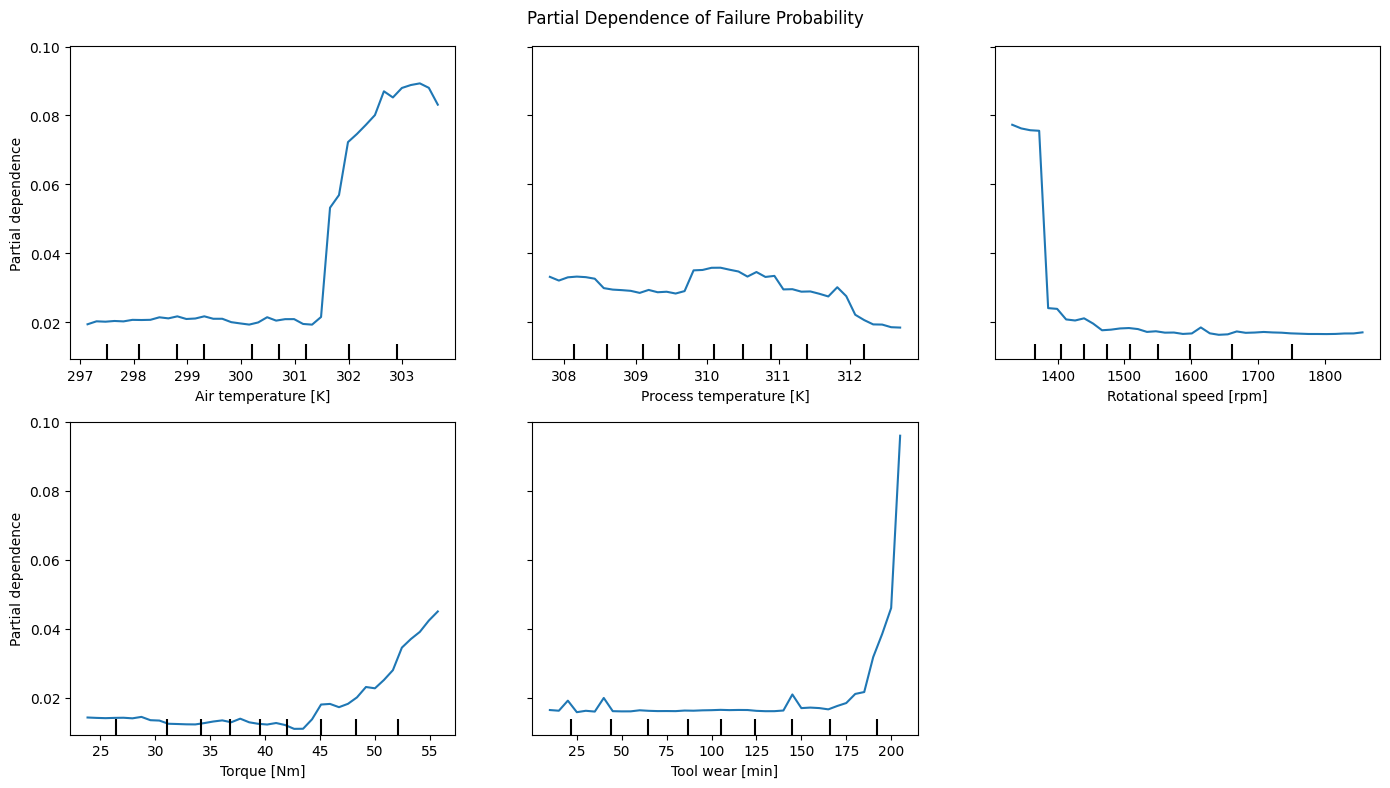

In [16]:
# Partial dependence of failure probability on each sensor
# A random sample of 1000 training rows keeps the calculation fast
pdp_sample = Xs_train.sample(n=1000, random_state=42)

fig, ax = plt.subplots(figsize=(14, 8))

PartialDependenceDisplay.from_estimator(
    sensor_forest,
    pdp_sample,
    features=sensor_columns,
    grid_resolution=40,
    n_cols=3,
    ax=ax
)

fig.suptitle("Partial Dependence of Failure Probability")
plt.tight_layout()
plt.show()

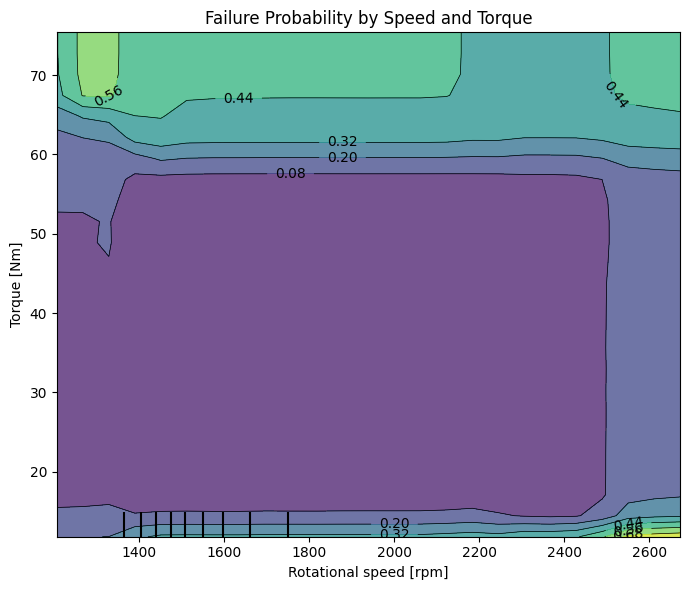

In [17]:
# Two way partial dependence: torque and rotational speed together
# The full range is used because the failures sit at the extremes:
# low speed with high torque, and high speed with low torque
fig, ax = plt.subplots(figsize=(7, 6))

PartialDependenceDisplay.from_estimator(
    sensor_forest,
    pdp_sample,
    features=[("Rotational speed [rpm]", "Torque [Nm]")],
    grid_resolution=25,
    percentiles=(0.0, 1.0),
    ax=ax
)

plt.title("Failure Probability by Speed and Torque")
plt.tight_layout()
plt.show()

In [18]:
# The importance and partial dependence plots point to physical quantities:
# power (torque x angular speed) and the gap between process and air temperature.
# These match the power failure and heat dissipation failure modes in the dataset.
engineered = X_sensors.copy()

engineered["Power [W]"] = (
    sensors["Torque [Nm]"] * sensors["Rotational speed [rpm]"] * 2 * np.pi / 60
)
engineered["Temperature difference [K]"] = (
    sensors["Process temperature [K]"] - sensors["Air temperature [K]"]
)
engineered["Strain [min Nm]"] = (
    sensors["Tool wear [min]"] * sensors["Torque [Nm]"]
)

Xe_train, Xe_test, ye_train, ye_test = train_test_split(
    engineered,
    y_sensors,
    test_size=0.20,
    random_state=42,
    stratify=y_sensors
)

engineered_forest = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

engineered_forest.fit(Xe_train, ye_train)

engineered_predictions = engineered_forest.predict(Xe_test)

sensor_f1 = f1_score(ys_test, sensor_predictions)
engineered_f1 = f1_score(ye_test, engineered_predictions)

print("F1 with raw sensors       :", round(sensor_f1, 3))
print("F1 with engineered features:", round(engineered_f1, 3))
print("Recall with raw sensors       :", round(recall_score(ys_test, sensor_predictions), 3))
print("Recall with engineered features:", round(recall_score(ye_test, engineered_predictions), 3))

F1 with raw sensors       : 0.648
F1 with engineered features: 0.843
Recall with raw sensors       : 0.5
Recall with engineered features: 0.75


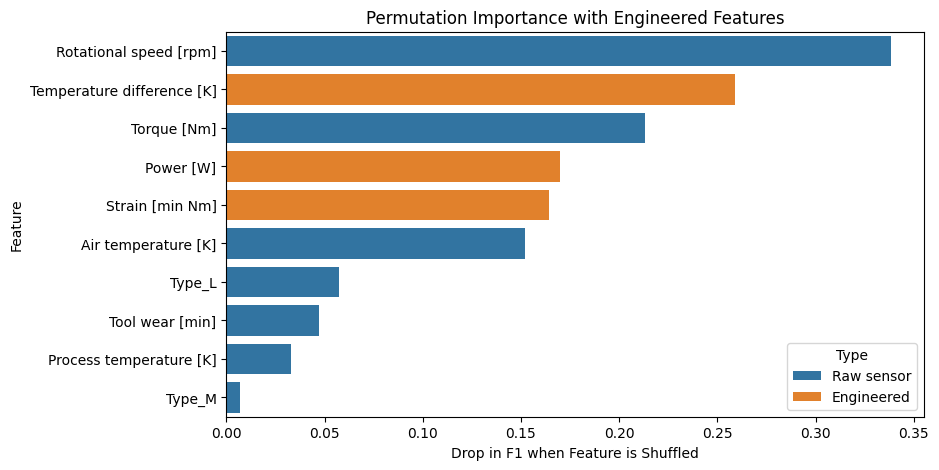

,Feature,Drop in F1,Type
2,Rotational speed [rpm],0.3382,Raw sensor
8,Temperature difference [K],0.2590,Engineered
3,Torque [Nm],0.2132,Raw sensor
7,Power [W],0.1698,Engineered
9,Strain [min Nm],0.1642,Engineered
0,Air temperature [K],0.1522,Raw sensor
5,Type_L,0.0572,Raw sensor
4,Tool wear [min],0.0474,Raw sensor
1,Process temperature [K],0.0330,Raw sensor
6,Type_M,0.0068,Raw sensor


In [19]:
engineered_permutation = permutation_importance(
    engineered_forest,
    Xe_test,
    ye_test,
    n_repeats=20,
    random_state=42,
    scoring="f1"
)

engineered_importance = pd.DataFrame({
    "Feature": engineered.columns,
    "Drop in F1": engineered_permutation.importances_mean
}).sort_values(by="Drop in F1", ascending=False)

engineered_importance["Type"] = np.where(
    engineered_importance["Feature"].isin(["Power [W]", "Temperature difference [K]", "Strain [min Nm]"]),
    "Engineered",
    "Raw sensor"
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=engineered_importance,
    x="Drop in F1",
    y="Feature",
    hue="Type",
    dodge=False
)

plt.title("Permutation Importance with Engineered Features")
plt.xlabel("Drop in F1 when Feature is Shuffled")
plt.ylabel("Feature")
plt.show()

engineered_importance.round(4)

In [20]:
print("FEATURE IMPORTANCE - SUMMARY")
print("----------------------------------")
print("Vehicle price (Random Forest, R2 %.3f)" % r2_score(yc_test, car_predictions))
print("  Top features by impurity   :", ", ".join(car_impurity_grouped["Original Feature"].head(3)))
print("  Top features by permutation:", ", ".join(car_permutation_df["Feature"].head(3)))
print("  Rank agreement (Spearman)  : %.2f" % rank_agreement)
print()
print("Machine failure (Random Forest, F1 %.3f)" % sensor_f1)
print("  Top sensors by permutation :", ", ".join(sensor_importance.index[:3]))
print("  Top engineered model feats :", ", ".join(engineered_importance["Feature"].head(3)))
print("  F1 after feature engineering: %.3f" % engineered_f1)

FEATURE IMPORTANCE - SUMMARY
----------------------------------
Vehicle price (Random Forest, R2 0.929)
  Top features by impurity   : curb-weight, engine-size, horsepower
  Top features by permutation: engine-size, curb-weight, horsepower
  Rank agreement (Spearman)  : 0.86

Machine failure (Random Forest, F1 0.648)
  Top sensors by permutation : Torque [Nm], Rotational speed [rpm], Air temperature [K]
  Top engineered model feats : Rotational speed [rpm], Temperature difference [K], Torque [Nm]
  F1 after feature engineering: 0.843
